In [1]:
import os

workdir = '/vast/ai_projects/Papenfuss_SVEnsemble2/model/'
os.chdir(workdir)
os.getcwd()

'/vast/ai_projects/Papenfuss_SVEnsemble2/model'

In [2]:
import copy
import importlib

In [3]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import pyranges as pr

import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve

In [4]:
import vcfparser as vcfp
import bndconvert as bndc

importlib.reload(vcfp)
importlib.reload(bndc)

<module 'bndconvert' from '/vast/ai_projects/Papenfuss_SVEnsemble2/model/bndconvert.py'>

In [5]:
pd.set_option('display.max_columns', None)

In [5]:
# I use reference derived by algorithm described by Kosugi
# With dgv version for year 2020 instead of 2016

# ref_path = '../reference/saved/NA12878.reference.tsv'
# ref_df = pd.read_csv(ref_path, sep='\t', index_col='Unnamed: 0')
# ref_df = ref_df[ref_df['ALT'] == 'deletion']

ref_path = 'data/NA12878_DGV-2016_LR-assembly.hg38.bed'
ref_df = pd.read_csv(ref_path, sep='\t', names=['Chromosome', 'Start', 'End', 'ALT'])
ref_df.loc[:, 'length'] = ref_df['End'] - ref_df['Start']
ref_df = ref_df[ref_df['ALT'] == 'DEL'] 

# ref_df.loc[:, 'ALT'] = '<DEL>'
ref_df.loc[:, 'is_in_ref'] = True
ref_df.loc[:, 'ID'] = ref_df['Chromosome'].astype(str) + ':' + ref_df['Start'].astype(str) + '-' + ref_df['End'].astype(str)

ref_df_pr = ref_df
# ref_df_pr = ref_df_pr[ref_df_pr.length > 50]


ref_df_pr

,Chromosome,Start,End,ALT,length,is_in_ref,ID
4,chr1,67901,68345,DEL,444,True,chr1:67901-68345
6,chr1,149392,149706,DEL,314,True,chr1:149392-149706
14,chr1,382344,382636,DEL,292,True,chr1:382344-382636
18,chr1,369349,369531,DEL,182,True,chr1:369349-369531
19,chr1,368749,369183,DEL,434,True,chr1:368749-369183
...,...,...,...,...,...,...,...
25332,chrY,23364741,23742759,DEL,378018,True,chrY:23364741-23742759
25333,chrY,23821643,24084364,DEL,262721,True,chrY:23821643-24084364
25334,chrY,24164942,24856589,DEL,691647,True,chrY:24164942-24856589
25335,chrY,24894982,26029114,DEL,1134132,True,chrY:24894982-26029114


In [6]:
gridss_callset_path = 'data/test_gridss_output.NA12878.vcf'
gridss_callset_raw = vcfp.parse_vcf(gridss_callset_path, line_limit=None)

Processed 0 entries                 Elapsed time: 2.09808349609375e-05 seconds.
Processed 100000 entries                 Elapsed time: 3.469996213912964 seconds.
Processed 200000 entries                 Elapsed time: 7.022686719894409 seconds.
Processed 300000 entries                 Elapsed time: 10.565877914428711 seconds.
Processed 400000 entries                 Elapsed time: 14.046382427215576 seconds.
Processed 500000 entries                 Elapsed time: 17.48909831047058 seconds.
Processed 600000 entries                 Elapsed time: 20.922120571136475 seconds.
Processed 700000 entries                 Elapsed time: 24.318877458572388 seconds.
Processed 800000 entries                 Elapsed time: 27.68635869026184 seconds.
Processed 900000 entries                 Elapsed time: 31.069161415100098 seconds.
Processed 1000000 entries                 Elapsed time: 34.38651084899902 seconds.
Finished processing. Processed 1007409 entries out of 1007410. Elapsed time: 52.27229142189026

In [7]:
gridss_callset_bps = bndc.bnd_to_event(gridss_callset_raw.iloc[:,])

In [28]:
gridss_callset_bps_pr = gridss_callset_bps.rename(columns={
    'CHROM': 'Chromosome',
    'POS': 'Start',
    'INFO_END': 'End'
})
# gridss_callset_bps_pr = gridss_callset_bps_pr[(gridss_callset_bps_pr.End - gridss_callset_bps_pr.Start) > 50]
# gridss_callset_bps_pr = gridss_callset_bps_pr[gridss_callset_bps_pr['FILTER_PASS']]
# gridss_callset_bps_pr = gridss_callset_bps_pr[(gridss_callset_bps_pr.FILTER_PASS)]

gridss_callset_bps_pr

,Chromosome,Start,ID,REF,LALT,QUAL,FILTER_ASSEMBLY_BIAS,FILTER_ASSEMBLY_ONLY,FILTER_ASSEMBLY_TOO_FEW_READ,FILTER_ASSEMBLY_TOO_SHORT,FILTER_INSUFFICIENT_SUPPORT,FILTER_LOW_MAPQ,FILTER_LOW_QUAL,FILTER_NO_ASSEMBLY,FILTER_NO_RP,FILTER_NO_SR,FILTER_REF,FILTER_SINGLE_SUPPORT,FILTER_SMALL_EVENT,FORMAT_ASRP,FORMAT_ASSR,FORMAT_BAQ,FORMAT_BASRP,FORMAT_BASSR,FORMAT_CASQ,FORMAT_GT,FORMAT_IC,FORMAT_IQ,FORMAT_QUAL,FORMAT_RP,FORMAT_RPQ,FORMAT_SR,FORMAT_SRQ,FORMAT_VF,INFO_SVLEN,INFO_ASRP,INFO_ASSR,INFO_BA,INFO_BAQ,INFO_BASRP,INFO_BASSR,INFO_BEID,INFO_BENAMES,INFO_BPNAMES,INFO_CAS,INFO_CASQ,INFO_CQ,INFO_EVENT,INFO_HOMLEN,INFO_IC,INFO_IMPRECISE,INFO_INSRM,INFO_INSRMP,INFO_INSRMRC,INFO_INSRMRO,INFO_INSRMRT,INFO_INSTAXID,INFO_IQ,INFO_MQ,INFO_MQN,INFO_MQX,INFO_RF,INFO_RP,INFO_RPQ,INFO_RSI,INFO_SELF,INFO_SI,INFO_SR,INFO_SRQ,INFO_SVTYPE,INFO_VF,FILTER_PASS,End,RALT,CHR2,ALT
150,chr1,1845834,gridss0fb_1029,N,A[chr1:1845864[,2725.38,0,0,0,0,0,0,0,0,0,0,0,0,0,0,64,0.00,0,0,0.00,.,12,636.13,2725.38,1,14.92,6,112.22,45\n,0,0,64,0,0.00,0,0,"asm0-59592,asm0-7673,asm0-7683",0,0,0,0.00,2725.38,gridss0fb_1029,18,12,0,0,0,0,0,0,0,636.13,60.00,60.00,60.00,0,1,14.92,0,0,0,6,112.22,DEL,45,True,1845863,]chr1:1845833]C,chr1,<DEL>
154,chr1,1955040,gridss0fb_1102,N,A[chr1:1955058[,374.77,0,0,0,0,0,0,1,0,0,0,0,0,0,0,11,0.00,0,0,0.00,.,3,122.97,374.77,0,0.00,0,0.00,11\n,0,0,11,0,0.00,0,0,asm0-8537,0,0,0,0.00,374.77,gridss0fb_1102,43,3,0,0,0,0,0,0,0,122.97,60.00,60.00,60.00,0,0,0.00,0,0,0,0,0.00,DEL,11,False,1955057,]chr1:1955039]A,chr1,<DEL>
156,chr1,2005917,gridss0fb_1143,N,C[chr1:2005937[,1697.97,0,0,0,0,0,0,0,0,0,0,0,0,0,0,44,0.00,0,0,0.00,.,10,422.84,1697.97,0,0.00,0,0.00,34\n,0,0,44,0,0.00,0,0,"asm0-60790,asm0-8915",0,0,0,0.00,1697.97,gridss0fb_1143,17,10,0,0,0,0,0,0,0,422.84,60.00,60.00,60.00,0,0,0.00,0,0,0,0,0.00,DEL,34,True,2005936,]chr1:2005916]T,chr1,<DEL>
160,chr1,2098103,gridss0fb_1212,N,G[chr1:2098113[,62.87,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0.00,0,0,0.00,.,2,62.87,62.87,0,0.00,0,0.00,2\n,0,0,0,0,0.00,0,0,0,0,0,0,0.00,62.87,gridss0fb_1212,4,2,0,0,0,0,0,0,0,62.87,45.00,30.00,60.00,0,0,0.00,0,0,0,0,0.00,DEL,2,False,2098112,]chr1:2098102]G,chr1,<DEL>
164,chr1,2189617,gridss0fb_1288,N,C[chr1:2189645[,418.53,0,0,0,0,0,0,1,0,0,0,0,0,0,2,10,0.00,0,0,0.00,.,2,102.05,418.53,2,29.75,1,19.10,11\n,0,2,10,0,0.00,0,0,"asm0-10093,asm0-61811",0,0,0,0.00,403.67,gridss0fb_1288,37,2,0,0,0,0,0,0,0,102.05,60.00,60.00,60.00,0,2,29.75,0,0,0,1,19.10,DEL,11,False,2189644,]chr1:2189616]G,chr1,<DEL>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
197155,chr1,91159223,gridss9fb_848,N,G[chr1:91159506[,3834.57,0,0,0,0,0,0,0,0,0,0,0,0,0,94,68,0.00,0,0,0.00,.,0,0.00,3834.57,47,706.96,24,463.01,77\n,0,94,68,0,0.00,0,0,"asm9-48562,asm9-5042",0,0,0,0.00,3804.31,gridss9fb_848,16,0,0,0,0,0,0,0,0,0.00,59.68,50.00,60.00,0,47,706.96,0,0,0,24,463.01,DEL,77,True,91159505,]chr1:91159222]A,chr1,<DEL>
197156,chr1,91168495,gridss9fb_853,N,G[chr1:91168519[,1570.37,0,0,0,0,0,0,0,0,0,0,0,0,0,1,42,0.00,0,0,0.00,.,8,367.77,1570.37,0,0.00,0,0.00,34\n,0,1,42,0,0.00,0,0,"asm9-48599,asm9-5077",0,0,0,0.00,1585.25,gridss9fb_853,21,8,0,0,0,0,0,0,0,367.77,55.20,45.00,60.00,0,0,0.00,0,0,0,0,0.00,DEL,34,True,91168518,]chr1:91168494]T,chr1,<DEL>
197158,chr1,91169310,gridss9fb_859,N,C[chr1:91169348[,1959.35,0,0,0,0,0,0,0,0,0,0,0,0,0,2,70,0.00,0,0,0.00,.,3,112.00,1959.35,0,0.00,20,378.07,47\n,0,2,70,0,0.00,0,0,"asm9-48592,asm9-5076",0,0,0,0.00,1959.35,gridss9fb_859,4,3,0,0,0,0,0,0,0,112.00,55.60,22.00,60.00,0,0,0.00,0,0,0,20,378.07,DEL,47,True,91169347,]chr1:91169309]G,chr1,<DEL>
197160,chr1,91169439,gridss9fb_861,N,A[chr1:91169449[,1891.49,0,0,0,0,0,0,0,0,0,0,0,0,0,0,29,0.00,0,0,0.00,.,29,945.75,1891.49,0,0.00,0,0.00,29\n,0,0,29,0,0.00,0,0,asm9-5075,0,0,0,0.00,1891.4

In [29]:
# We need to join the PU callsets to corresponding training datasets
# Since the callsets do not contain coordinate and ID information
# They need to be concated to training data first (which has the ID info)
# And to the original caller callset to fetch the coordinate inf (using the added IDs)
overlapped_df_path = 'saved/gridss_overlaps.tsv'
callset_overlapped_df = pd.read_csv(overlapped_df_path, sep='\t', index_col='ID')
y_duplessis = pd.read_csv('saved/y_duplessis.csv', index_col='index', names=['index', 'y_duplessis'], skiprows=1)
callset_overlapped_df = pd.concat([callset_overlapped_df.reset_index(), y_duplessis], axis=1)[['ID', 'y_duplessis']]

duplessis_callset_pr = gridss_callset_bps_pr[['Chromosome', 'Start', 'End', 'ID']].merge(callset_overlapped_df, on='ID', how='left')
duplessis_callset_pr.loc[:, 'length'] = duplessis_callset_pr.End - duplessis_callset_pr.Start
# duplessis_callset_pr = duplessis_callset_pr[duplessis_callset_pr.length > 50]
# duplessis_callset_pr[duplessis_callset_pr]

In [30]:
duplessis_callset_pr

,Chromosome,Start,End,ID,y_duplessis,length
0,chr1,1845834,1845863,gridss0fb_1029,0.00,29
1,chr1,1955040,1955057,gridss0fb_1102,0.00,17
2,chr1,2005917,2005936,gridss0fb_1143,0.00,19
3,chr1,2098103,2098112,gridss0fb_1212,0.00,9
4,chr1,2189617,2189644,gridss0fb_1288,0.00,27
...,...,...,...,...,...,...
49385,chr1,91159223,91159505,gridss9fb_848,0.85,282
49386,chr1,91168495,91168518,gridss9fb_853,0.00,23
49387,chr1,91169310,91169347,gridss9fb_859,0.01,37
49388,chr1,91169439,91169448,gridss9fb_861,0.00,9


In [31]:
overlapped_df_path = 'saved/gridss_overlaps.tsv'
callset_overlapped_df = pd.read_csv(overlapped_df_path, sep='\t', index_col='ID')
y_enoto = pd.read_csv('saved/y_enoto.csv', index_col='index', names=['index', 'y_enoto'], skiprows=1)
callset_overlapped_df = pd.concat([callset_overlapped_df.reset_index(), y_enoto], axis=1)[['ID', 'y_enoto']]

enoto_callset_pr = gridss_callset_bps_pr[['Chromosome', 'Start', 'End', 'ID']].merge(callset_overlapped_df, on='ID', how='left')
enoto_callset_pr.loc[:, 'length'] = enoto_callset_pr.End - enoto_callset_pr.Start
# enoto_callset_pr = enoto_callset_pr[enoto_callset_pr.length > 50]

In [32]:
# What I have: 
# - GRIDSS callset (for now DELs only)
# - 2 PU callsets (Trained to detect DELs)
#   
# - High confidence callset (DELs only)
# - gnomad data
#
# What I want:
# - full join of all except gnomad
#   with overlaps reported between high confidence and all other callsets
#
# How to do it:
# 1. Convert all to prs
# 2. Left-join each pr to high confidence
#    In the joined datasets there may be multiple overlaps
# 3. To resolve them, filter by overlap fraction (>80% overlap)
#    Variants with >80% overlap are considered the same, others are considered different.
#    Report all the joined variants as lists.
# 4. Concatenate the non-joined variants as if they do not overlap

In [33]:
def full_callset_join(ref_df, call_df):

    try:
        ref_df_pr = pr.PyRanges(ref_df)
    except Exception as e:
        if str(e) == 'Object is already a PyRange.':
            ref_df_pr = ref_df
            pass
        else:
            raise

    try:
        call_df_pr = pr.PyRanges(call_df)
    except Exception as e:
        if str(e) == 'Object is already a PyRange.':
            call_df_pr = call_df
            pass
        else:
            raise
    
    ref_call_pr = ref_df_pr.join(call_df_pr, report_overlap=True)
    
    ref_call_pr = ref_call_pr.df.reset_index(drop=True)
    ref_call_pr.loc[:, 'overlap_frac'] = ref_call_pr.Overlap * 2 / (ref_call_pr.End - ref_call_pr.Start + ref_call_pr.End_b - ref_call_pr.Start_b)
    ref_call_pr = ref_call_pr[ref_call_pr.overlap_frac > 0.8].sort_values(by='overlap_frac', ascending=False).drop_duplicates(subset=['ID'], keep='first').drop_duplicates(subset=['ID_b'], keep='first')
    
    # overlapping_ids_gridss_ref = ref_gridss_pr[ref_gridss_pr.overlap_frac > 0.8][['ID']]
    # overlapping_ids_gridss_callset = ref_gridss_pr[ref_gridss_pr.overlap_frac > 0.8][['ID_b']]
    
    overlapping_ids_ref = ref_call_pr['ID']
    overlapping_ids_call = ref_call_pr['ID_b']
    
    ref_df_pr_nonoverlapping = ref_df_pr.df[~ref_df_pr.df['ID'].isin(overlapping_ids_ref)].reset_index(drop=True)
    call_df_pr_nonoverlapping = call_df_pr.df[~call_df_pr.df['ID'].isin(overlapping_ids_call)].reset_index(drop=True).rename(columns={
        'ID': 'ID_b'
    })
    call_df_pr_nonoverlapping.loc[:, 'is_in_ref'] = False
    
    ref_call_pr = pd.concat([ref_call_pr, ref_df_pr_nonoverlapping, call_df_pr_nonoverlapping])
    
    # ref_call_pr.loc[:, 'ref_overlap_detected'] = (ref_call_pr.overlap_frac > 0.8) & (~ref_call_pr.overlap_frac.isna())
    # ref_call_pr.loc[:, 'is_in_ref'] = (~ref_call_pr.is_in_ref.isna()).astype(bool)

    return ref_call_pr

In [34]:
# ref_df=ref_df_pr
# call_df=gridss_callset_bps_pr

# try:
#     ref_df_pr = pr.PyRanges(ref_df)
# except Exception as e:
#     if str(e) == 'Object is already a PyRange.':
#         ref_df_pr = ref_df
#         pass
#     else:
#         raise

# try:
#     call_df_pr = pr.PyRanges(call_df)
# except Exception as e:
#     if str(e) == 'Object is already a PyRange.':
#         call_df_pr = call_df
#         pass
#     else:
#         raise

# ref_call_pr = ref_df_pr.join(call_df_pr, report_overlap=True)
# ref_call_pr = ref_call_pr.df.reset_index(drop=True)
# ref_call_pr.loc[:, 'overlap_frac'] = ref_call_pr.Overlap * 2 / (ref_call_pr.End - ref_call_pr.Start + ref_call_pr.End_b - ref_call_pr.Start_b)

# # ref_call_pr = ref_call_pr[ref_call_pr.overlap_frac > 0.8].sort_values(by='overlap_frac', ascending=False).drop_duplicates(subset=['ID'], keep='first').drop_duplicates(subset=['ID_b'], keep='first')
# ref_call_pr = ref_call_pr.sort_values(by='overlap_frac', ascending=False)#.drop_duplicates(subset=['ID'], keep='first').drop_duplicates(subset=['ID_b'], keep='first')
# ref_call_pr = ref_call_pr[ref_call_pr.overlap_frac > 0.8]

# # # overlapping_ids_gridss_ref = ref_gridss_pr[ref_gridss_pr.overlap_frac > 0.8][['ID']]
# # # overlapping_ids_gridss_callset = ref_gridss_pr[ref_gridss_pr.overlap_frac > 0.8][['ID_b']]

# # overlapping_ids_ref = ref_call_pr['ID']
# # overlapping_ids_call = ref_call_pr['ID_b']

# # ref_df_pr_nonoverlapping = ref_df_pr.df[~ref_df_pr.df['ID'].isin(overlapping_ids_ref)].reset_index(drop=True)
# # call_df_pr_nonoverlapping = call_df_pr.df[~call_df_pr.df['ID'].isin(overlapping_ids_call)].reset_index(drop=True).rename(columns={
# #     'ID': 'ID_b'
# # })
# # call_df_pr_nonoverlapping.loc[:, 'is_in_ref'] = False

# # ref_call_pr = pd.concat([ref_call_pr, ref_df_pr_nonoverlapping, call_df_pr_nonoverlapping])

# ref_call_pr.loc[:, 'length_b'] = ref_call_pr['End_b'] - ref_call_pr['Start_b']

# ref_call_pr[['Start', 'End', 'length', 'Start_b', 'End_b', 'length_b', 'Overlap', 'FILTER_PASS']]

# ref_call_pr.value_counts('FILTER_PASS')


In [35]:
ref_gridss = full_callset_join(ref_df=ref_df, call_df=gridss_callset_bps_pr)
ref_gridss_h = full_callset_join(ref_df=ref_df, call_df=gridss_callset_bps_pr[gridss_callset_bps_pr.FILTER_PASS])
ref_duplessis = full_callset_join(ref_df=ref_df, call_df=duplessis_callset_pr)
ref_enoto = full_callset_join(ref_df=ref_df, call_df=enoto_callset_pr)

In [36]:
# ref_gridss[ref_gridss['overlap_frac'] > 0.8]

In [37]:
ref_gridss = ref_gridss[~ref_gridss.QUAL.isna()]
ref_gridss_h = ref_gridss_h[~ref_gridss_h.QUAL.isna()]
ref_duplessis = ref_duplessis[~ref_duplessis.y_duplessis.isna()]
ref_enoto = ref_enoto[~ref_enoto.y_enoto.isna()]

In [80]:
ref_gridss.loc[ref_gridss.QUAL.isna(), 'QUAL'] = -1
ref_gridss_h.loc[ref_gridss_h.QUAL.isna(), 'QUAL'] = -1
ref_duplessis.loc[ref_duplessis.y_duplessis.isna(), 'y_duplessis'] = -1
ref_enoto.loc[ref_enoto.y_enoto.isna(), 'y_enoto'] = -1
# ref_gridss_h = ref_gridss_h[~ref_gridss_h.QUAL.isna()]
# ref_duplessis = ref_duplessis[~ref_duplessis.y_duplessis.isna()]
# ref_enoto = ref_enoto[~ref_enoto.y_enoto.isna()]

<Axes: title={'center': 'logQUAL'}, xlabel='is_in_ref'>

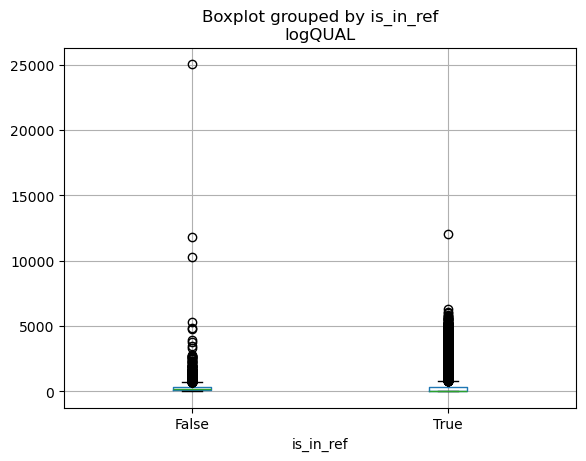

In [81]:
ref_gridss.loc[:, 'logQUAL'] = ref_gridss.QUAL
ref_gridss.boxplot(column='logQUAL', by='is_in_ref')

In [82]:
# ref_gridss = ref_gridss[
#     ((ref_gridss.End - ref_gridss.Start) > 50) & (((ref_gridss.End_b - ref_gridss.Start_b) > 50) | (ref_gridss.End_b.isna()))
# ]
# ref_duplessis = ref_duplessis[(((ref_duplessis.End - ref_duplessis.Start) > 50) & ((ref_duplessis.End_b - ref_duplessis.Start_b) > 50)) | ref_duplessis.End.isna()  | ref_duplessis.Start.isna() | ref_duplessis.End_b.isna() | ref_duplessis.Start_b.isna()]

In [83]:
test_df = pd.concat([ref_duplessis.is_in_ref, ref_duplessis.y_duplessis, ref_duplessis.ID], axis=1)

In [84]:
test_df.loc[:, 'ID_present'] = ~test_df.ID.isna()

In [85]:
test_df

,is_in_ref,y_duplessis,ID,ID_present
39200,True,0.795,chr21:35642666-35642870,True
19050,True,0.335,chr4:68732220-68732572,True
39074,True,0.235,chr20:2379258-2379962,True
39088,True,0.875,chr20:17122807-17123153,True
8830,True,0.310,chr2:125008984-125010670,True
...,...,...,...,...
3079,False,0.005,NaN,False
3080,False,0.090,NaN,False
3081,False,0.000,NaN,False
3082,False,0.040,NaN,False


<Axes: title={'center': 'y_duplessis'}, xlabel='is_in_ref'>

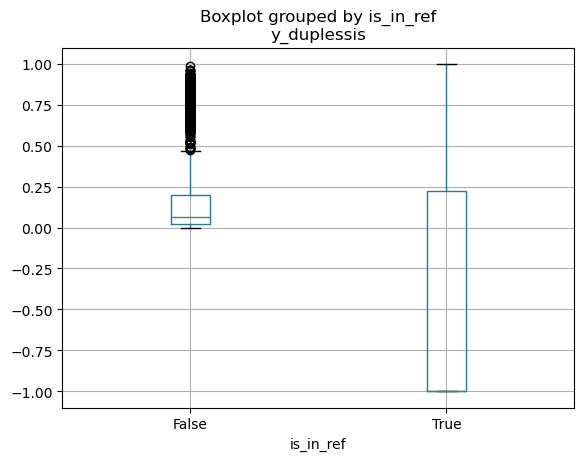

In [86]:
test_df.boxplot(column='y_duplessis', by='is_in_ref')

In [87]:
test_df.groupby('is_in_ref').describe()

y_duplessis                                                     
                count      mean       std  min   25%    50%      75%   max
is_in_ref                                                                 
False          3084.0  0.188315  0.262518  0.0  0.02  0.065  0.20125  0.99
True           9043.0 -0.521942  0.787953 -1.0 -1.00 -1.000  0.22500  1.00

In [38]:
def plot_roc_curve(true_y, y_prob):
    """
    plots the roc curve based of the probabilities
    """

    fpr, tpr, thresholds = roc_curve(true_y, y_prob, pos_label=True)
    plt.plot(fpr, tpr)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')

In [39]:
roc_auc_score(ref_duplessis.is_in_ref, ref_duplessis.y_duplessis)

np.float64(0.993121184286218)

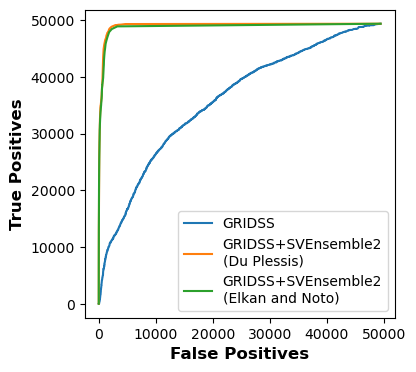

In [40]:
fpr_gridss, tpr_gridss, thresholds_gridss = roc_curve(ref_gridss.is_in_ref, ref_gridss.QUAL, pos_label=True)
tpnum_gridss = tpr_gridss*ref_gridss.shape[0]
fpnum_gridss = fpr_gridss*ref_gridss.shape[0]
fpr_duplessis, tpr_duplessis, thresholds_duplessis = roc_curve(ref_duplessis.is_in_ref, ref_duplessis.y_duplessis, pos_label=True)
tpnum_duplessis = tpr_duplessis*ref_duplessis.shape[0]
fpnum_duplessis = fpr_duplessis*ref_gridss.shape[0]
fpr_enoto, tpr_enoto, thresholds_enoto = roc_curve(ref_enoto.is_in_ref, ref_enoto.y_enoto, pos_label=True)
tpnum_enoto = tpr_enoto*ref_enoto.shape[0]
fpnum_enoto = fpr_enoto*ref_gridss.shape[0]

fig, ax = plt.subplots(figsize=(4,4))

ax.plot(fpnum_gridss, tpnum_gridss, label='GRIDSS')
ax.plot(fpnum_duplessis, tpnum_duplessis, label='GRIDSS+SVEnsemble2\n(Du Plessis)')
ax.plot(fpnum_enoto, tpnum_enoto, label='GRIDSS+SVEnsemble2\n(Elkan and Noto)')
ax.legend(loc=4)

plt.xlabel('False Positives', size='large', weight=700)
plt.ylabel('True Positives', size='large', weight=700)

plt.savefig('figs/roc_full.png', bbox_inches='tight', dpi=300)

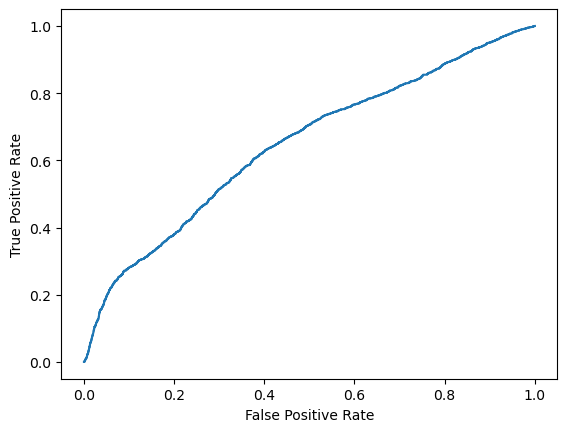

In [41]:
plot_roc_curve(ref_gridss_h.is_in_ref, ref_gridss_h.QUAL)

In [42]:
def plot_precision_recall_curve(true_y, y_prob):
    """
    plots the roc curve based of the probabilities
    """

    prec, rec, thresholds = precision_recall_curve(true_y, y_prob)
    plt.plot(prec, rec)
    plt.xlabel('Recall')
    plt.ylabel('Precision')

Text(0, 0.5, 'Precision')

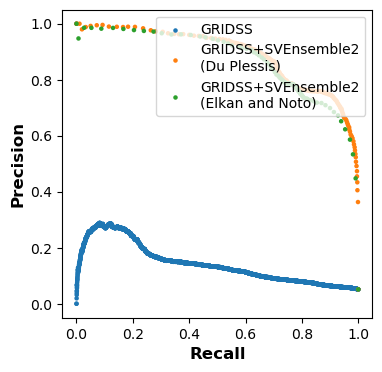

In [43]:
prec_gridss, rec_gridss, thresholds_gridss = precision_recall_curve(ref_gridss.is_in_ref, ref_gridss.QUAL, pos_label=True, drop_intermediate=True)
# tp_gridss = prec_gridss * (ref_gridss.shape[0])
prec_duplessis, rec_duplessis, thresholds_duplessis = precision_recall_curve(ref_duplessis.is_in_ref, ref_duplessis.y_duplessis, pos_label=True, drop_intermediate=True)
prec_enoto, rec_enoto, thresholds_enoto = precision_recall_curve(ref_enoto.is_in_ref, ref_enoto.y_enoto, pos_label=True, drop_intermediate=True)

fig, ax = plt.subplots(figsize=(4, 4))

ax.scatter(rec_gridss, prec_gridss, label='GRIDSS', s=[5]*len(rec_gridss))
ax.scatter(rec_duplessis,prec_duplessis, label='GRIDSS+SVEnsemble2\n(Du Plessis)', s=[5]*len(rec_duplessis))
ax.scatter(rec_enoto, prec_enoto, label='GRIDSS+SVEnsemble2\n(Elkan and Noto)', s=[5]*len(rec_enoto))
ax.legend(loc=1)

plt.xlabel('Recall', size='large', weight=700)
plt.ylabel('Precision', size='large', weight=700)

# plot_precision_recall_curve(ref_duplessis.is_in_ref, ref_duplessis.y_duplessis)
# print(roc_auc_score((ref_duplessis.is_in_ref, ref_duplessis.y_duplessis)))

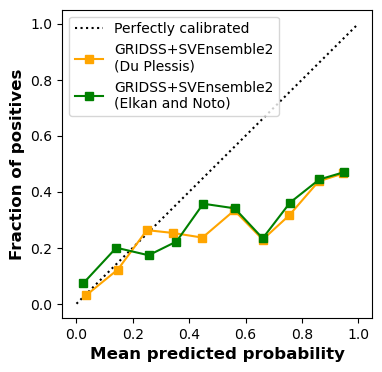

In [76]:
from sklearn.calibration import calibration_curve, CalibrationDisplay
prob_true, prob_pred = calibration_curve(ref_duplessis.is_in_ref, ref_duplessis.y_duplessis, n_bins=10)
disp_duplessis = CalibrationDisplay(prob_true, prob_pred, ref_duplessis.y_duplessis)

prob_true, prob_pred = calibration_curve(ref_enoto.is_in_ref, ref_enoto.y_enoto, n_bins=10)
disp_enoto = CalibrationDisplay(prob_true, prob_pred, ref_enoto.y_enoto)

fig, ax = plt.subplots(figsize=(4, 4))
disp_duplessis.plot(ax=ax, label='GRIDSS+SVEnsemble2\n(Du Plessis)', color='orange')
disp_enoto.plot(ax=ax, label='GRIDSS+SVEnsemble2\n(Elkan and Noto)', color='green')

ax.legend(loc=2)

plt.xlabel('Mean predicted probability', size='large', weight=700)
plt.ylabel('Fraction of positives', size='large', weight=700)

plt.savefig('figs/calibcurve.duplessis_enoto.png', bbox_inches='tight', dpi=300)

In [49]:
# y_score = classifier.decision_function(X_test)
# from sklearn.metrics import PrecisionRecallDisplay

# display = PrecisionRecallDisplay.from_predictions(
#     ref_duplessis.is_in_ref, ref_duplessis.y_duplessis, name="PU (DuPlessis correction)", plot_chance_level=True
# )
# _ = display.ax_.set_title("2-class Precision-Recall curve")


In [50]:
# display = PrecisionRecallDisplay.from_predictions(
#     ref_gridss.is_in_ref, ref_gridss.QUAL, name="GRIDSS", plot_chance_level=True
# )
# _ = display.ax_.set_title("2-class Precision-Recall curve")


In [ ]:
fig = plt.figure(figsize=(10, 10))
gs = GridSpec(4, 2)
colors = plt.get_cmap("Dark2")

ax_calibration_curve = fig.add_subplot(gs[:2, :2])
calibration_displays = {}
for i, (clf, name) in enumerate(clf_list):
    clf.fit(X_train, y_train)
    display = CalibrationDisplay.from_estimator(
        clf,
        X_test,
        y_test,
        n_bins=10,
        name=name,
        ax=ax_calibration_curve,
        color=colors(i),
    )
    calibration_displays[name] = display

ax_calibration_curve.grid()
ax_calibration_curve.set_title("Calibration plots (Naive Bayes)")

# Add histogram
grid_positions = [(2, 0), (2, 1), (3, 0), (3, 1)]
for i, (_, name) in enumerate(clf_list):
    row, col = grid_positions[i]
    ax = fig.add_subplot(gs[row, col])

    ax.hist(
        calibration_displays[name].y_prob,
        range=(0, 1),
        bins=10,
        label=name,
        color=colors(i),
    )
    ax.set(title=name, xlabel="Mean predicted probability", ylabel="Count")

plt.tight_layout()
plt.show()